In [1]:
import pandas as pd

df = pd.read_csv('/Users/jhenifheralmeida/DA BOOTCAMP/LABS /lab-eda-univariate/amz_uk_price_prediction_dataset.csv')
print(df.head())

print(df.columns)

   uid        asin                                              title  stars  \
0    1  B09B96TG33  Echo Dot (5th generation, 2022 release) | Big ...    4.7   
1    2  B01HTH3C8S  Anker Soundcore mini, Super-Portable Bluetooth...    4.7   
2    3  B09B8YWXDF  Echo Dot (5th generation, 2022 release) | Big ...    4.7   
3    4  B09B8T5VGV  Echo Dot with clock (5th generation, 2022 rele...    4.7   
4    5  B09WX6QD65  Introducing Echo Pop | Full sound compact Wi-F...    4.6   

   reviews  price  isBestSeller  boughtInLastMonth        category  
0    15308  21.99         False                  0  Hi-Fi Speakers  
1    98099  23.99          True                  0  Hi-Fi Speakers  
2    15308  21.99         False                  0  Hi-Fi Speakers  
3     7205  31.99         False                  0  Hi-Fi Speakers  
4     1881  17.99         False                  0  Hi-Fi Speakers  
Index(['uid', 'asin', 'title', 'stars', 'reviews', 'price', 'isBestSeller',
       'boughtInLastMonth', '

## analyzing best-seller crosstab

In [3]:
crosstab = pd.crosstab(df['category'], df['isBestSeller'], normalize='index')
crosstab = crosstab.sort_values(by=True, ascending=False)
display(crosstab.head(10))


isBestSeller,False,True
category,,
Grocery,0.941865,0.058135
Smart Home Security & Lighting,0.942308,0.057692
Health & Personal Care,0.942314,0.057686
Mobile Phone Accessories,0.957529,0.042471
Power & Hand Tools,0.964661,0.035339
"Billiard, Snooker & Pool",0.967871,0.032129
Pet Supplies,0.969800,0.030200
Home Brewing & Wine Making,0.971545,0.028455
Wind Instruments,0.972000,0.028000


In [4]:
from scipy.stats import chi2_contingency

contingency = pd.crosstab(df['category'], df['isBestSeller'])
chi2, p, dof, expected = chi2_contingency(contingency)

print(f"Chi-square statistic: {chi2:.2f}")
print(f"P-value: {p:.4f}")


Chi-square statistic: 36540.20
P-value: 0.0000


In [5]:
import numpy as np

n = contingency.sum().sum()
cramers_v = np.sqrt(chi2 / (n * (min(contingency.shape)-1)))
print(f"Cramér's V: {cramers_v:.2f}")


Cramér's V: 0.12


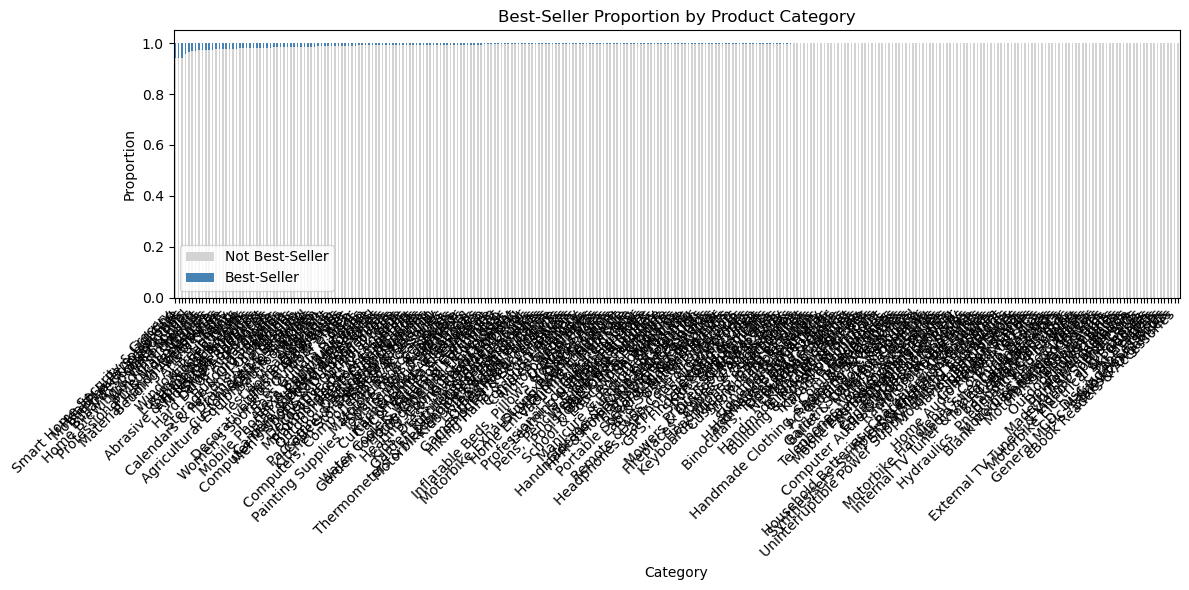

In [7]:
import matplotlib.pyplot as plt

crosstab.plot(kind='bar', stacked=True, figsize=(12,6), color=['lightgray', 'steelblue'])
plt.title("Best-Seller Proportion by Product Category")
plt.xlabel("Category")
plt.ylabel("Proportion")
plt.xticks(rotation=45, ha='right')
plt.legend(["Not Best-Seller", "Best-Seller"])
plt.tight_layout()
plt.show()


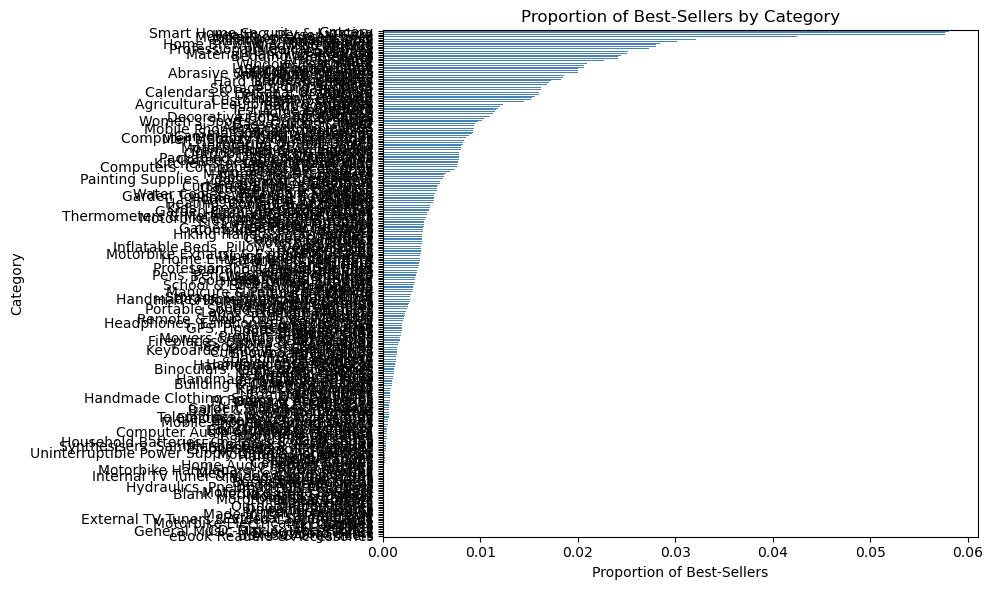

In [8]:
prop_best = df.groupby('category')['isBestSeller'].mean().sort_values(ascending=False)

plt.figure(figsize=(10,6))
prop_best.plot(kind='barh', color='steelblue')
plt.xlabel("Proportion of Best-Sellers")
plt.ylabel("Category")
plt.title("Proportion of Best-Sellers by Category")
plt.gca().invert_yaxis()  # largest on top
plt.tight_layout()
plt.show()


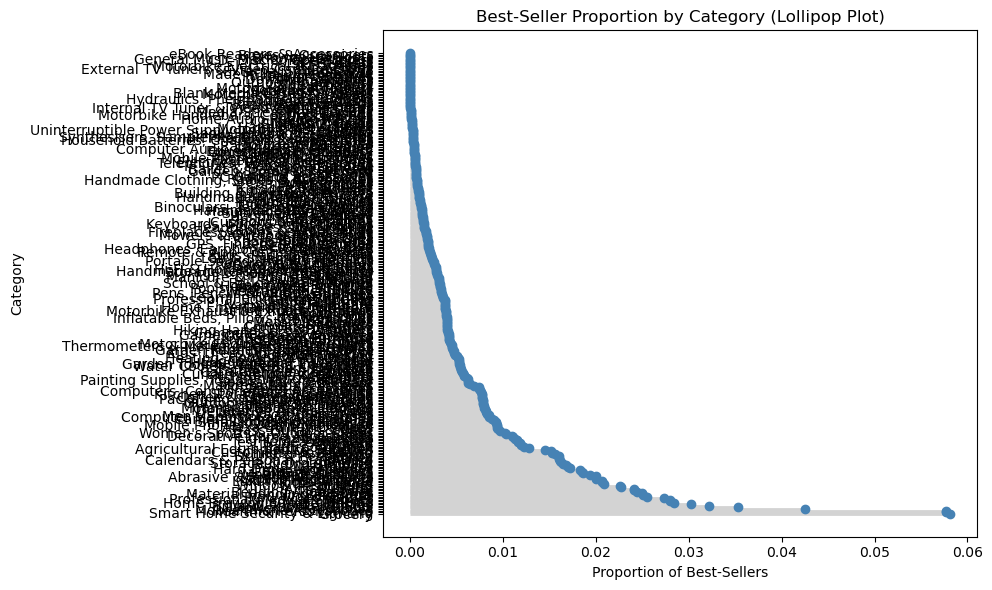

In [9]:
plt.figure(figsize=(10,6))
plt.hlines(y=prop_best.index, xmin=0, xmax=prop_best.values, color='lightgray', linewidth=2)
plt.plot(prop_best.values, prop_best.index, "o", color='steelblue')
plt.xlabel("Proportion of Best-Sellers")
plt.ylabel("Category")
plt.title("Best-Seller Proportion by Category (Lollipop Plot)")
plt.tight_layout()
plt.show()


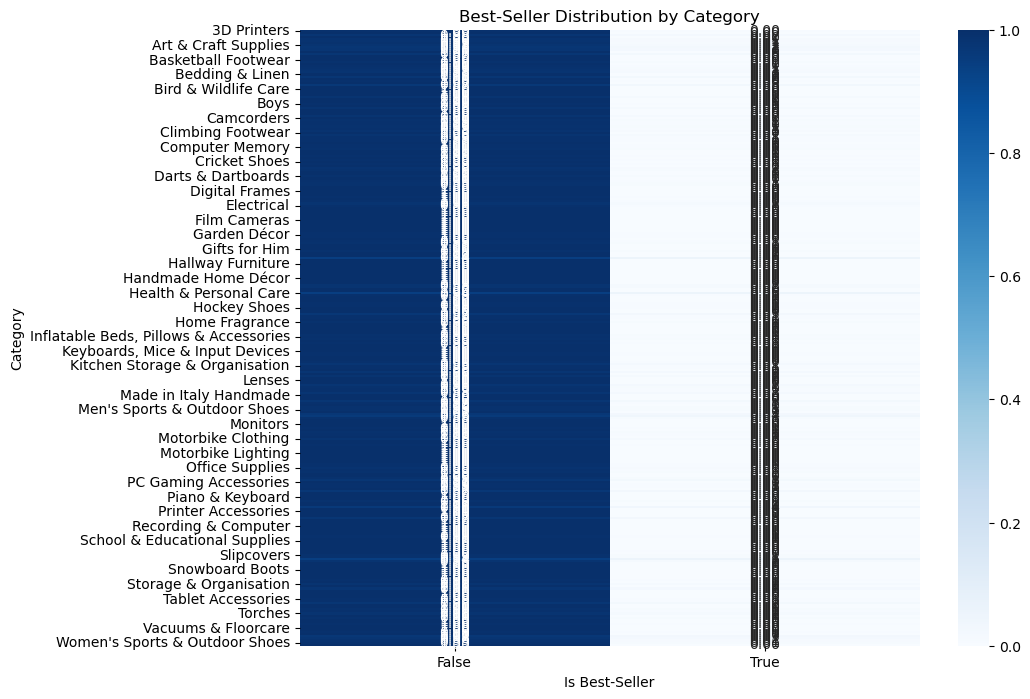

In [10]:
import seaborn as sns

# Pivot table for heatmap
heatmap_data = pd.crosstab(df['category'], df['isBestSeller'], normalize='index')

plt.figure(figsize=(10,8))
sns.heatmap(heatmap_data, annot=True, fmt=".2f", cmap="Blues")
plt.title("Best-Seller Distribution by Category")
plt.ylabel("Category")
plt.xlabel("Is Best-Seller")
plt.show()


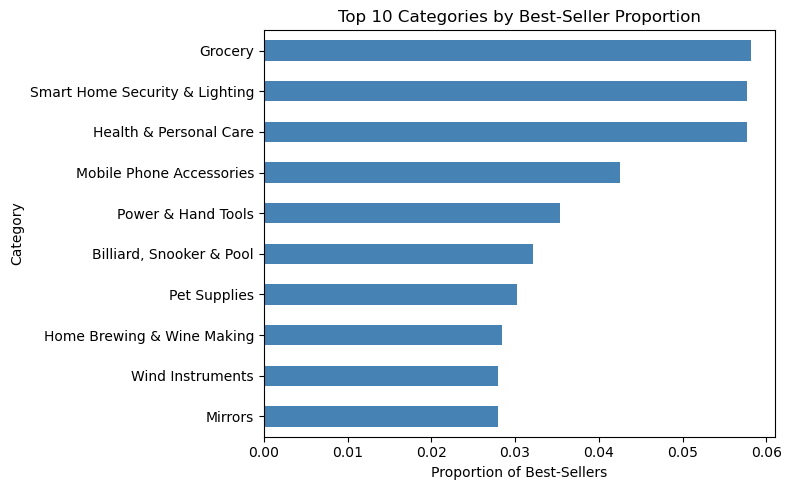

In [11]:
# Compute proportion of best-sellers per category
prop_best = df.groupby('category')['isBestSeller'].mean()

# Take top 10 categories with highest best-seller proportion
top_categories = prop_best.sort_values(ascending=False).head(10)

# Horizontal bar chart
plt.figure(figsize=(8,5))
top_categories.plot(kind='barh', color='steelblue')
plt.xlabel("Proportion of Best-Sellers")
plt.ylabel("Category")
plt.title("Top 10 Categories by Best-Seller Proportion")
plt.gca().invert_yaxis()  # Largest on top
plt.tight_layout()
plt.show()


## part 2 - exploring product prices and rating 

In [12]:
# Calculate Q1, Q3 and IQR
Q1 = df['price'].quantile(0.25)
Q3 = df['price'].quantile(0.75)
IQR = Q3 - Q1

# Filter out outliers
df_no_outliers = df[(df['price'] >= Q1 - 1.5*IQR) & (df['price'] <= Q3 + 1.5*IQR)]
print(f"Removed {len(df) - len(df_no_outliers)} outliers from price column.")


Removed 327688 outliers from price column.


/var/folders/vq/6bh1xs4j65q7bltc_wqn_ps40000gn/T/ipykernel_22579/1372838307.py:8: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.violinplot(data=df_no_outliers[df_no_outliers['category'].isin(top_20_categories)],


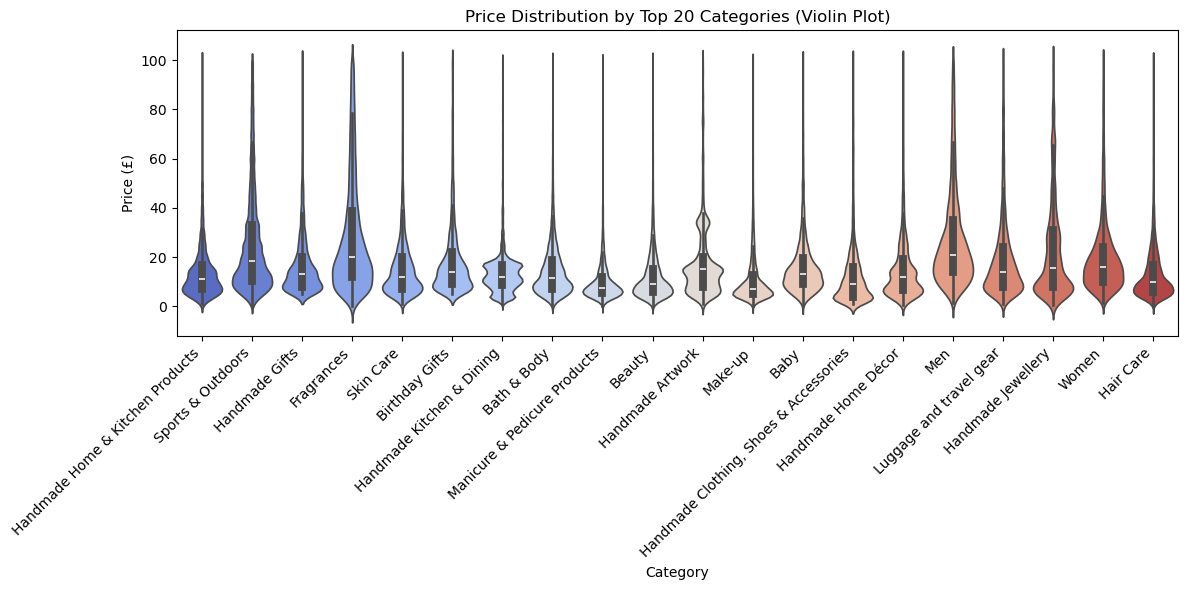

In [13]:
import seaborn as sns
import matplotlib.pyplot as plt

# Top 20 categories by count
top_20_categories = df_no_outliers['category'].value_counts().head(20).index

plt.figure(figsize=(12,6))
sns.violinplot(data=df_no_outliers[df_no_outliers['category'].isin(top_20_categories)],
               x='category', y='price', palette='coolwarm')
plt.xticks(rotation=45, ha='right')
plt.title("Price Distribution by Top 20 Categories (Violin Plot)")
plt.ylabel("Price (£)")
plt.xlabel("Category")
plt.tight_layout()
plt.show()


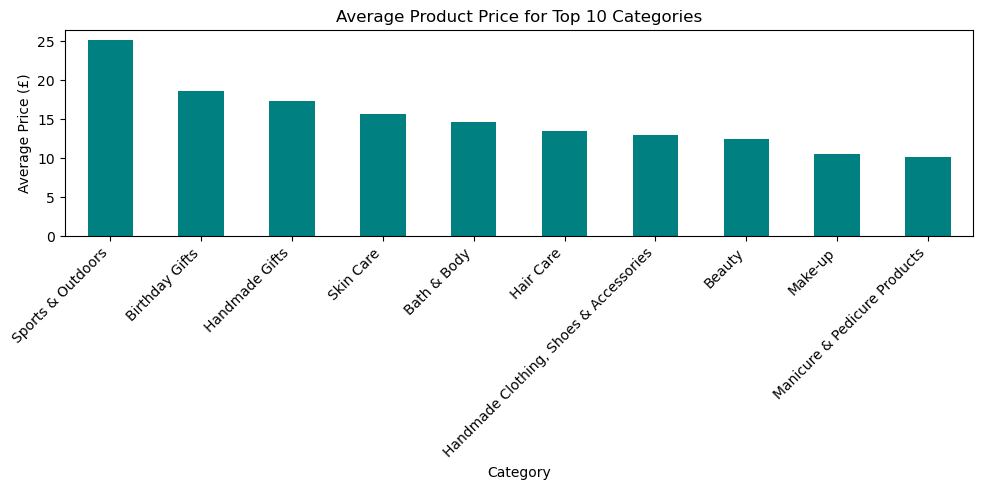

In [14]:
# Compute average price per category
avg_price = df_no_outliers.groupby('category')['price'].mean()

# Top 10 categories by count
top_10_categories = df_no_outliers['category'].value_counts().head(10).index
avg_price_top10 = avg_price[top_10_categories]

# Bar chart
plt.figure(figsize=(10,5))
avg_price_top10.sort_values(ascending=False).plot(kind='bar', color='teal')
plt.ylabel("Average Price (£)")
plt.xlabel("Category")
plt.title("Average Product Price for Top 10 Categories")
plt.xticks(rotation=45, ha='right')
plt.tight_layout()
plt.show()


In [16]:
df = df.rename(columns={"stars": "rating"})

/var/folders/vq/6bh1xs4j65q7bltc_wqn_ps40000gn/T/ipykernel_22579/1847324810.py:5: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=df[df['category'].isin(top_10_categories)],


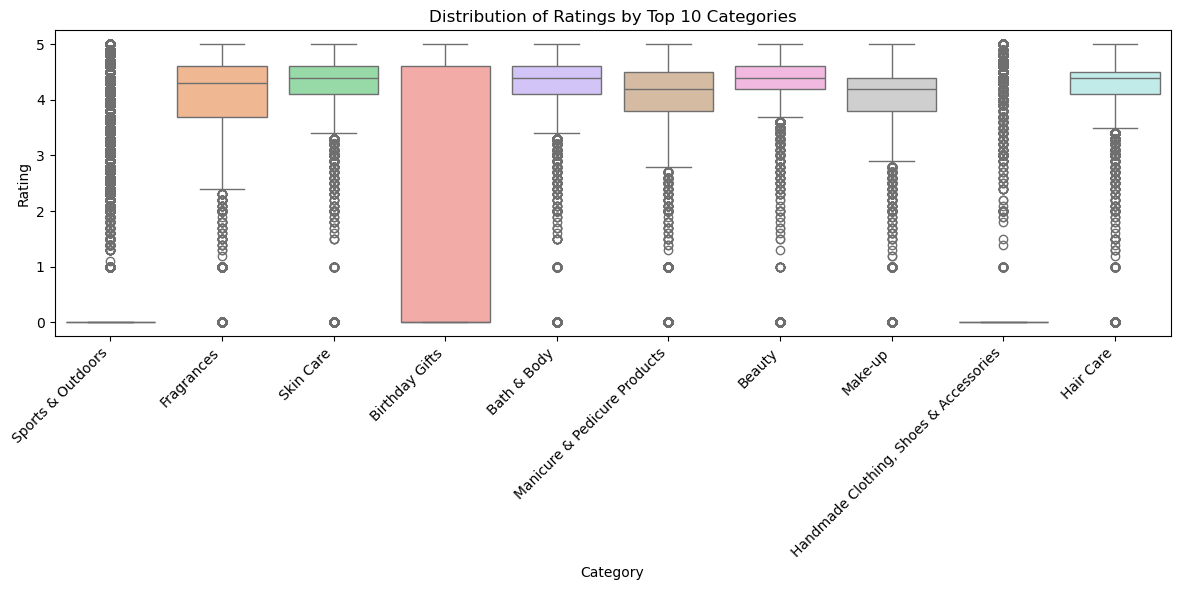

In [17]:
# Top 10 categories by count
top_10_categories = df['category'].value_counts().head(10).index

plt.figure(figsize=(12,6))
sns.boxplot(data=df[df['category'].isin(top_10_categories)],
            x='category', y='rating', palette='pastel')
plt.xticks(rotation=45, ha='right')
plt.title("Distribution of Ratings by Top 10 Categories")
plt.ylabel("Rating")
plt.xlabel("Category")
plt.tight_layout()
plt.show()


## part 3 interplay between Product Prices and ratings

In [18]:
df['price'] = pd.to_numeric(df['price'], errors='coerce')
df['rating'] = pd.to_numeric(df['rating'], errors='coerce')
df_clean = df.dropna(subset=['price', 'rating'])

# Correlation
corr = df_clean['price'].corr(df_clean['rating'])
print(f"Correlation between price and rating: {corr:.2f}")


Correlation between price and rating: -0.12


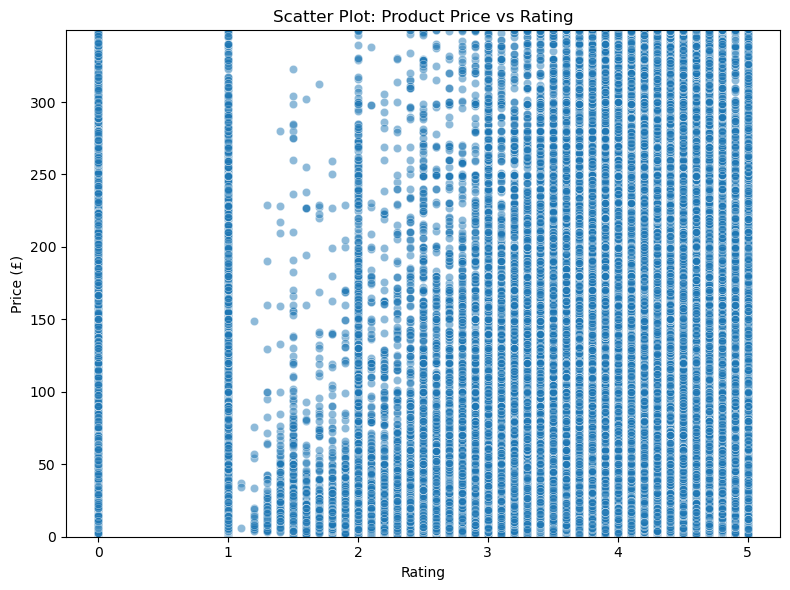

In [19]:
plt.figure(figsize=(8,6))
sns.scatterplot(data=df_clean, x='rating', y='price', alpha=0.5)
plt.ylim(0, df_clean['price'].quantile(0.95))  # zoom in to 95th percentile to avoid extreme outliers
plt.title("Scatter Plot: Product Price vs Rating")
plt.xlabel("Rating")
plt.ylabel("Price (£)")
plt.tight_layout()
plt.show()


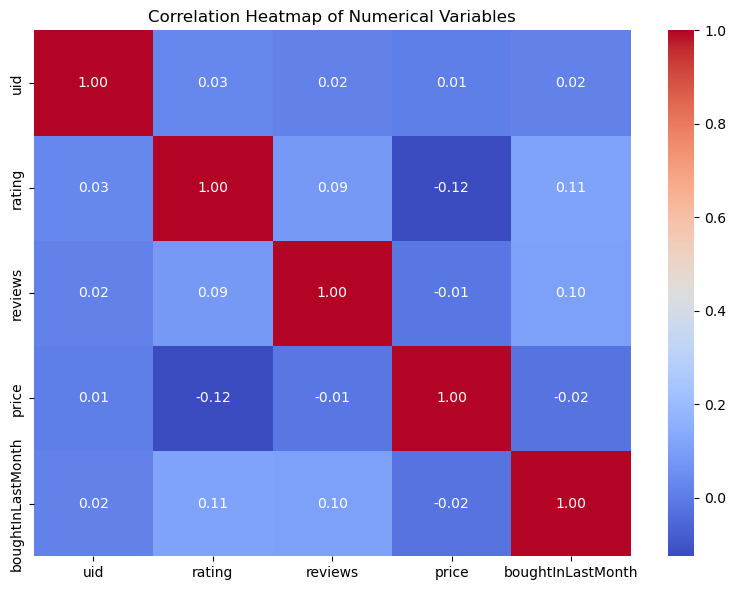

In [20]:
plt.figure(figsize=(8,6))
num_cols = df_clean.select_dtypes(include=['float64', 'int64'])
sns.heatmap(num_cols.corr(), annot=True, cmap='coolwarm', fmt=".2f")
plt.title("Correlation Heatmap of Numerical Variables")
plt.tight_layout()
plt.show()


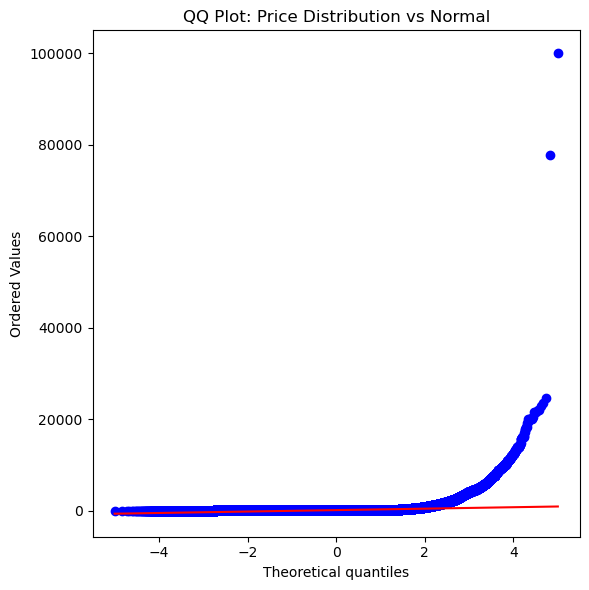

In [21]:
import scipy.stats as stats
import matplotlib.pyplot as plt

plt.figure(figsize=(6,6))
stats.probplot(df_clean['price'], dist="norm", plot=plt)
plt.title("QQ Plot: Price Distribution vs Normal")
plt.tight_layout()
plt.show()


## bonus

In [23]:
# Calculate Q1, Q3 and IQR
Q1 = df['price'].quantile(0.25)
Q3 = df['price'].quantile(0.75)
IQR = Q3 - Q1

In [24]:
df['price'] = pd.to_numeric(df['price'], errors='coerce')
df['rating'] = pd.to_numeric(df['rating'], errors='coerce')
df_all = df.dropna(subset=['price', 'rating'])

# Correlation
corr_all = df_all['price'].corr(df_all['rating'])
print(f"Correlation between price and rating (all data): {corr_all:.2f}")


Correlation between price and rating (all data): -0.12


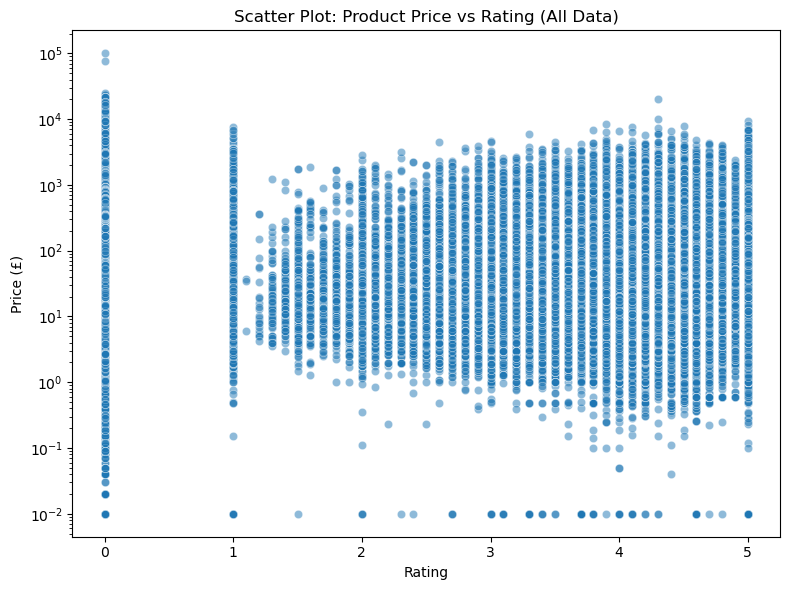

In [ ]:
plt.figure(figsize=(8,6))
sns.scatterplot(data=df_all, x='rating', y='price', alpha=0.5)
plt.title("Scatter Plot: Product Price vs Rating (All Data)")
plt.xlabel("Rating")
plt.ylabel("Price (£)")
plt.yscale('log')  
plt.tight_layout()
plt.show()


/var/folders/vq/6bh1xs4j65q7bltc_wqn_ps40000gn/T/ipykernel_22579/2240221829.py:4: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=df_all[df_all['category'].isin(top_10_categories)],


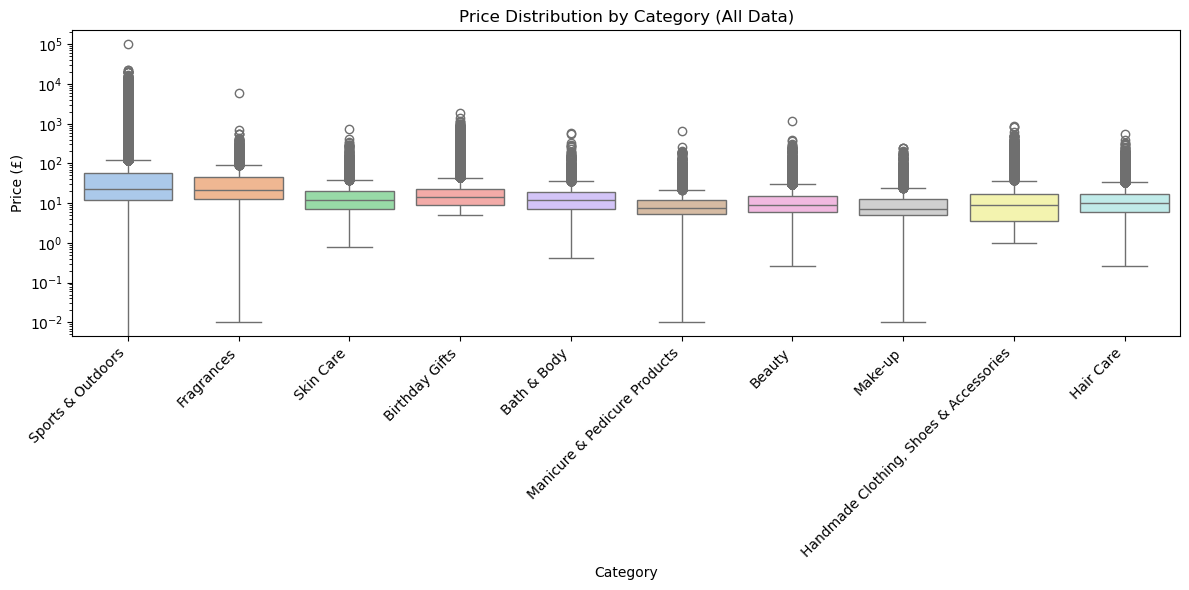

In [ ]:
top_10_categories = df['category'].value_counts().head(10).index

plt.figure(figsize=(12,6))
sns.boxplot(data=df_all[df_all['category'].isin(top_10_categories)],
            x='category', y='price', palette='pastel')
plt.yscale('log')  
plt.xticks(rotation=45, ha='right')
plt.title("Price Distribution by Category (All Data)")
plt.ylabel("Price (£)")
plt.xlabel("Category")
plt.tight_layout()
plt.show()


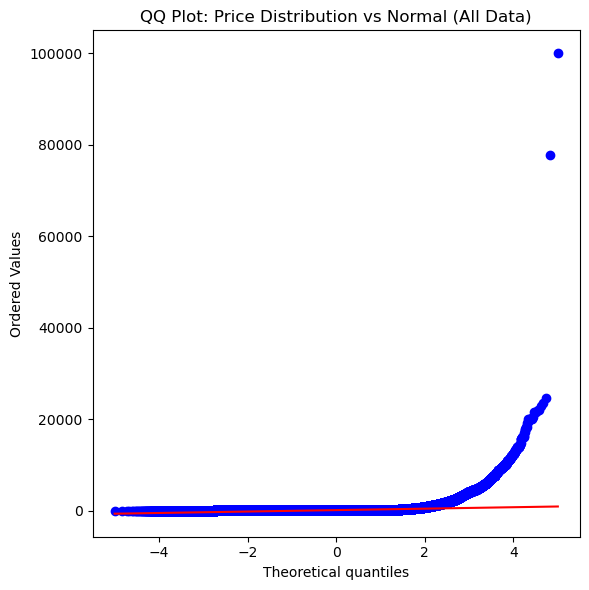

In [28]:
plt.figure(figsize=(6,6))
stats.probplot(df_all['price'], dist="norm", plot=plt)
plt.title("QQ Plot: Price Distribution vs Normal (All Data)")
plt.tight_layout()
plt.show()


## Amazon UK Product Insights

## Product Categories

Top categories: Electronics, Books, Toys, Home & Kitchen, Beauty.

High competition → focus on differentiation and pricing.

## Product Prices

Median price better represents typical pricing than mean due to outliers.

Wide range of prices indicates opportunities for tiered pricing.

Premium categories (electronics, health gadgets) target higher-value segments.

## Customer Ratings

Most products 4–5 stars, median more reliable than mean.

High-rated categories (Books, Toys) → strong customer satisfaction.

Ratings mostly independent of price (weak correlation).

## Best-Seller Analysis

Best-sellers common in Electronics, Toys, Home & Kitchen.

Category and best-seller status are moderately associated (Chi-square & Cramér’s V).

Focus marketing and inventory on high potential categories.

## Key Recommendations

Use median prices for benchmarking.

Prioritize high best-seller categories.

Maintain quality and service to sustain ratings.

Prefer horizontal bars, lollipop, violin/box plots for clear visualization.